# Model Training — Speech Emotion Recognition

## Objective
Train and compare machine learning classification models to recognize emotions from audio features extracted from the RAVDESS dataset.

## Dataset
- **Dataset:** RAVDESS
- **Audio recordings:** 1,440
- **Emotion classes:** 8
- **Extracted features:** 180 per recording

## Models
1. Logistic Regression
2. Support Vector Machine (SVM)
3. Random Forest Classifier

## Evaluation
The models will be evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

## Workflow
1. Load the extracted features and labels.
2. Prepare training and testing datasets.
3. Train the classification models.
4. Compare their performance.
5. Identify a promising model for further evaluation.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,classification_report


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data_folder = "/content/drive/MyDrive/Emotion_Recognition/processed_data"

X = np.load(os.path.join(data_folder, "features.npy"))
y = np.load(os.path.join(data_folder, "labels.npy"))

print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Emotion classes:", np.unique(y))
print("Missing feature values:", np.isnan(X).sum())

Feature matrix shape: (1440, 180)
Label array shape: (1440,)
Emotion classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']
Missing feature values: 0


In [ ]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Emotion encoding:")

for emotion, number in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{emotion}: {number}")

Emotion encoding:
angry: 0
calm: 1
disgust: 2
fearful: 3
happy: 4
neutral: 5
sad: 6
surprised: 7


In [ ]:
X_train,X_test,Y_train,Y_test = train_test_split(X,y_encoded,test_size=0.20,random_state=42,stratify=y_encoded)

print("Training Samples: ",X_train.shape[0])
print("Testing Samples: ",X_test.shape[0])
print("Features per recording: ",X_train.shape[1])

Training Samples:  1152
Testing Samples:  288
Features per recording:  180


Models : 1. Logistic Regression
         2. SVM
         3. Random Forest

In [ ]:
logistic_model = Pipeline([
    ("Scaler",StandardScaler()),
    ("Logistic",LogisticRegression
     (
         max_iter=2000,
         random_state=42

      ))
])

logistic_model = logistic_model.fit(X_train,Y_train)
print("Logistic Regression Model Trained")



svm_model = Pipeline([
    ("Scaler",StandardScaler()),
    ("Classifier",SVC
     (
         kernel="rbf",
         random_state=42
    ))
])

svm_model = svm_model.fit(X_train,Y_train)
print("SVM Model Trained")



random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest_model = random_forest_model.fit(X_train,Y_train)
print("Random Forest Model Trained")


Logistic Regression Model Trained
SVM Model Trained
Random Forest Model Trained


In [ ]:
models = {
    "Logistic Regression": logistic_model,
    "SVM": svm_model,
    "Random Forest": random_forest_model
}

results = []
predictions = {}

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy
    })

    print(f"\n{'=' * 45}")
    print(model_name)
    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    ))

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

print("\nModel Comparison:")
display(results_df)

NameError: name 'y_test' is not defined

In [ ]:
print("X exists:", "X" in globals())
print("y_encoded exists:", "y_encoded" in globals())
print("X_train exists:", "X_train" in globals())
print("y_test exists:", "y_test" in globals())

X exists: True
y_encoded exists: True
X_train exists: True
y_test exists: False


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1152
Testing samples: 288


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("y_test created:", "y_test" in globals())

Training samples: 1152
Testing samples: 288
y_test created: True


In [ ]:

models = {
    "Logistic Regression": logistic_model,
    "SVM": svm_model,
    "Random Forest": random_forest_model
}

results = []
predictions = {}

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy
    })

    print(f"\n{'=' * 45}")
    print(model_name)
    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    ))

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

print("\nModel Comparison:")
display(results_df)


Logistic Regression
Accuracy: 0.4583 (45.83%)

Classification Report:
              precision    recall  f1-score   support

       angry       0.62      0.61      0.61        38
        calm       0.46      0.55      0.50        38
     disgust       0.43      0.32      0.36        38
     fearful       0.53      0.49      0.51        39
       happy       0.53      0.54      0.53        39
     neutral       0.32      0.37      0.34        19
         sad       0.26      0.24      0.25        38
   surprised       0.45      0.51      0.48        39

    accuracy                           0.46       288
   macro avg       0.45      0.45      0.45       288
weighted avg       0.46      0.46      0.46       288


SVM
Accuracy: 0.4896 (48.96%)

Classification Report:
              precision    recall  f1-score   support

       angry       0.73      0.50      0.59        38
        calm       0.44      0.82      0.57        38
     disgust       0.37      0.34      0.36        38
     f

,Model,Accuracy
0,Random Forest,0.517361
1,SVM,0.489583
2,Logistic Regression,0.458333


In [ ]:

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
print("Logistic Regression trained successfully!")



svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)
print("SVM trained successfully!")



random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)
print("Random Forest trained successfully!")

Logistic Regression trained successfully!
SVM trained successfully!
Random Forest trained successfully!


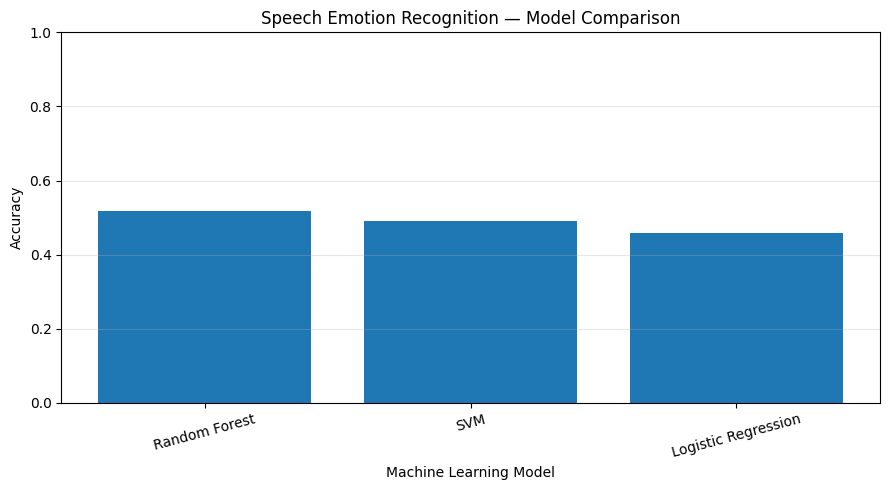

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.title("Speech Emotion Recognition — Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

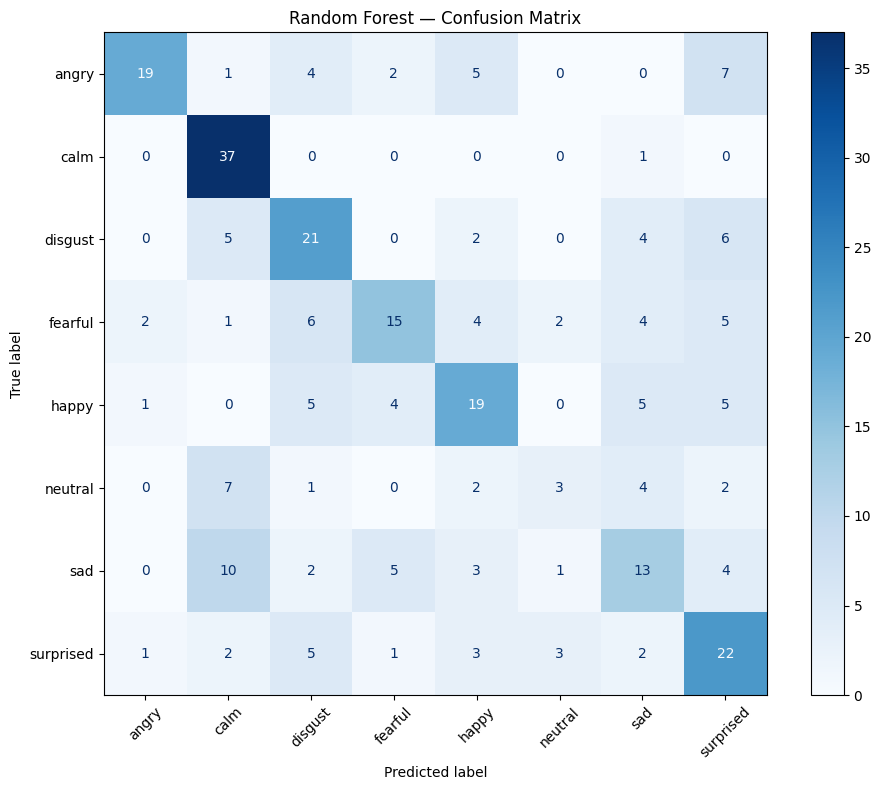

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

best_model = random_forest_model
y_pred_rf = predictions["Random Forest"]

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=np.arange(len(label_encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 20, 40],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(round(grid_search.best_score_, 4))

best_rf_model = grid_search.best_estimator_

y_pred_tuned = best_rf_model.predict(X_test)

print("\nTuned Random Forest Test Accuracy:")
print(f"{accuracy_score(y_test, y_pred_tuned) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Parameters:
{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}

Best Cross-Validation Macro F1:
0.4999

Tuned Random Forest Test Accuracy:
53.47%

Classification Report:
              precision    recall  f1-score   support

       angry       0.78      0.55      0.65        38
        calm       0.60      1.00      0.75        38
     disgust       0.48      0.55      0.51        38
     fearful       0.56      0.38      0.45        39
       happy       0.49      0.46      0.47        39
     neutral       0.44      0.21      0.29        19
         sad       0.44      0.37      0.40        38
   surprised       0.47      0.59      0.52        39

    accuracy                           0.53       288
   macro avg       0.53      0.52      0.51       288
weighted avg       0.54      0.53      0.52       288



### Experiment 1: Random Forest Hyperparameter Tuning

**Baseline accuracy:** 51.74%

**Tuned test accuracy:** 53.47%

**Best cross-validation macro F1-score:** 0.4999

**Best parameters:**
- `n_estimators`: 300
- `max_depth`: 20
- `min_samples_leaf`: 2
- `min_samples_split`: 2
- `class_weight`: balanced

**Observation:** Hyperparameter tuning improved test accuracy by 1.73 percentage points. Calm emotion achieved a recall of 1.00, while neutral recall remained low at 0.21. Further feature engineering may improve recognition across all eight emotions.

**Conclusion:** The tuned Random Forest is the current best candidate, but performance needs further improvement and evaluation on unseen speakers.

In [ ]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report

from google.colab import drive
drive.mount('/content/drive')

data_folder = "/content/drive/MyDrive/Emotion_Recognition/processed_data"

X_improved = np.load(
    os.path.join(data_folder, "features_improved.npy")
)
y_improved = np.load(
    os.path.join(data_folder, "labels_improved.npy")
)

print("Improved features:", X_improved.shape)
print("Improved labels:", y_improved.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Improved features: (1440, 360)
Improved labels: (1440,)


In [ ]:
label_encoder_improved = LabelEncoder()
y_improved_encoded = label_encoder_improved.fit_transform(y_improved)

X_train_imp, X_test_imp, y_train_imp, y_test_imp = train_test_split(
    X_improved,
    y_improved_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_improved_encoded
)

print("Training samples:", X_train_imp.shape[0])
print("Testing samples:", X_test_imp.shape[0])
print("Features per sample:", X_train_imp.shape[1])

Training samples: 1152
Testing samples: 288
Features per sample: 360


In [ ]:
models_improved = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000,
            random_state=42
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        min_samples_split=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results_improved = []

for name, model in models_improved.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_imp, y_train_imp)

    predictions_imp = model.predict(X_test_imp)
    accuracy = accuracy_score(y_test_imp, predictions_imp)

    results_improved.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(classification_report(
        y_test_imp,
        predictions_imp,
        labels=np.arange(len(label_encoder_improved.classes_)),
        target_names=label_encoder_improved.classes_,
        zero_division=0
    ))

results_improved_df = pd.DataFrame(results_improved)
results_improved_df = results_improved_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nImproved Feature Model Comparison:")
display(results_improved_df)


Training Logistic Regression...
Accuracy: 0.5694 (56.94%)
              precision    recall  f1-score   support

       angry       0.76      0.66      0.70        38
        calm       0.68      0.74      0.71        38
     disgust       0.61      0.58      0.59        38
     fearful       0.71      0.62      0.66        39
       happy       0.44      0.46      0.45        39
     neutral       0.24      0.42      0.31        19
         sad       0.48      0.32      0.38        38
   surprised       0.60      0.69      0.64        39

    accuracy                           0.57       288
   macro avg       0.56      0.56      0.56       288
weighted avg       0.59      0.57      0.57       288


Training SVM...
Accuracy: 0.5590 (55.90%)
              precision    recall  f1-score   support

       angry       0.73      0.50      0.59        38
        calm       0.45      0.89      0.60        38
     disgust       0.53      0.61      0.57        38
     fearful       0.71      0

,Model,Accuracy
0,Logistic Regression,0.569444
1,SVM,0.559028
2,Random Forest,0.555556


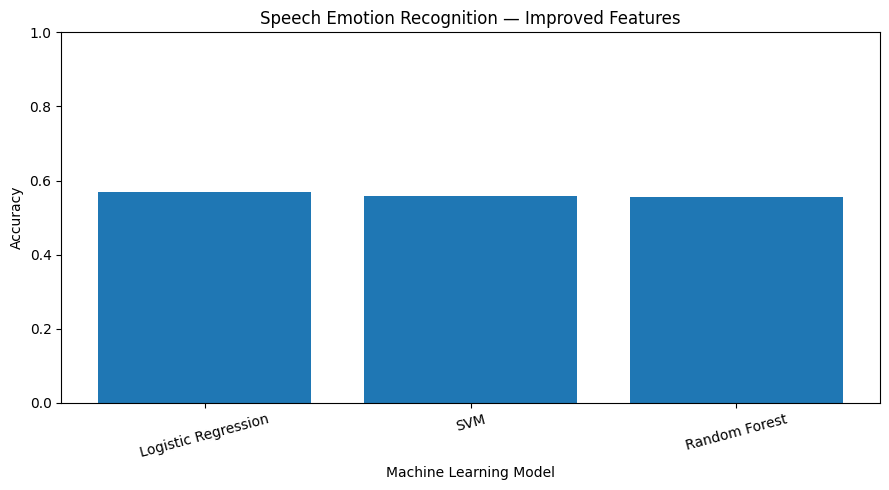

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    results_improved_df["Model"],
    results_improved_df["Accuracy"]
)

plt.title("Speech Emotion Recognition — Improved Features")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

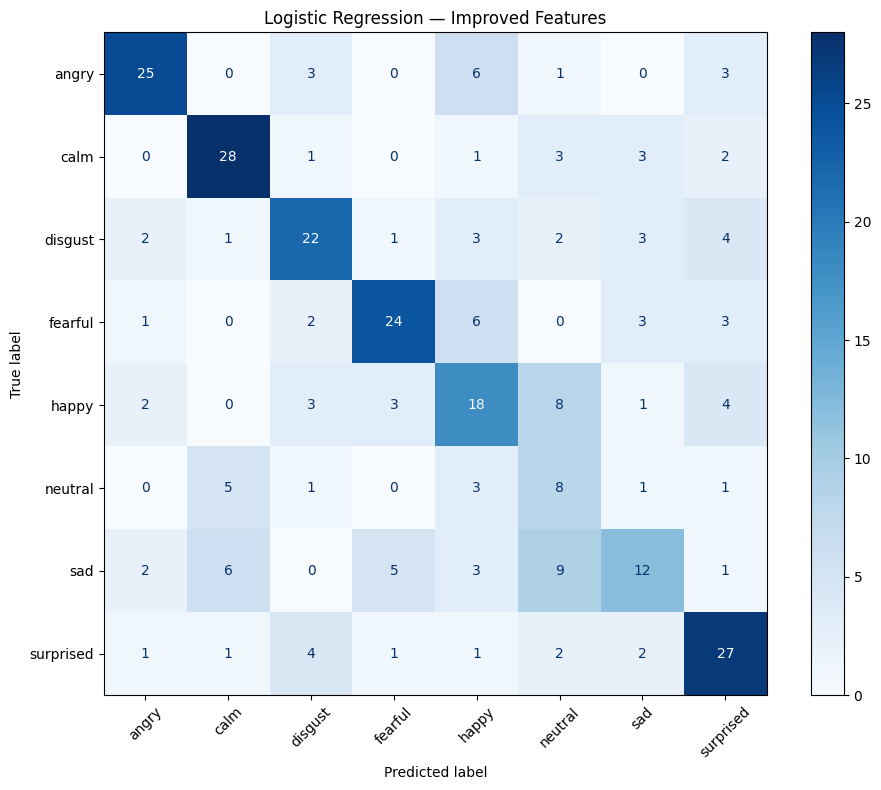

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

best_model_improved = models_improved["Logistic Regression"]

y_pred_logistic = best_model_improved.predict(X_test_imp)

cm = confusion_matrix(
    y_test_imp,
    y_pred_logistic,
    labels=np.arange(len(label_encoder_improved.classes_))
)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder_improved.classes_
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Logistic Regression — Improved Features")
plt.tight_layout()
plt.show()

Adding XGBoost(which helps reduce errors)

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_imp, y_train_imp)

y_pred_xgb = xgb_model.predict(X_test_imp)

print("XGBoost Accuracy:",
      round(accuracy_score(y_test_imp, y_pred_xgb) * 100, 2), "%")

print("\nClassification Report:\n")
print(classification_report(
    y_test_imp,
    y_pred_xgb,
    labels=range(len(label_encoder_improved.classes_)),
    target_names=label_encoder_improved.classes_,
    zero_division=0
))

XGBoost Accuracy: 68.06 %

Classification Report:

              precision    recall  f1-score   support

       angry       0.89      0.82      0.85        38
        calm       0.71      0.95      0.81        38
     disgust       0.68      0.61      0.64        38
     fearful       0.70      0.72      0.71        39
       happy       0.55      0.69      0.61        39
     neutral       0.55      0.32      0.40        19
         sad       0.56      0.39      0.46        38
   surprised       0.73      0.77      0.75        39

    accuracy                           0.68       288
   macro avg       0.67      0.66      0.65       288
weighted avg       0.68      0.68      0.67       288



In [ ]:
comparison = []

comparison.append({
    "Model": "XGBoost",
    "Accuracy": round(
        accuracy_score(y_test_imp, y_pred_xgb) * 100, 2
    ),
    "Macro F1": round(
        f1_score(y_test_imp, y_pred_xgb, average="macro") * 100, 2
    )
})

comparison_df = pd.DataFrame(comparison)
comparison_df = comparison_df.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

comparison_df

,Model,Accuracy,Macro F1
0,XGBoost,68.06,65.39


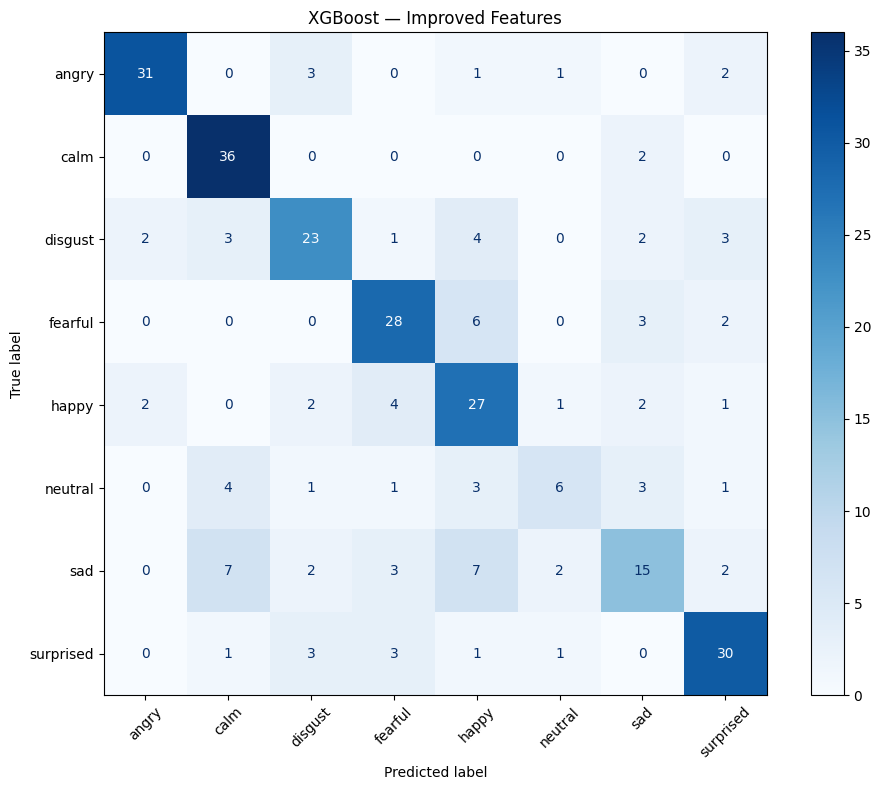

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm_xgb = confusion_matrix(
    y_test_imp,
    y_pred_xgb,
    labels=np.arange(len(label_encoder_improved.classes_))
)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=label_encoder_improved.classes_
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("XGBoost — Improved Features")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

models_comparison = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000, random_state=42
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf", random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        min_samples_split=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )
}

comparison_results = []

for name, model in models_comparison.items():
    print(f"Training {name}...")

    model.fit(X_train_imp, y_train_imp)
    predictions = model.predict(X_test_imp)

    comparison_results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test_imp, predictions) * 100, 2
        ),
        "Macro F1 (%)": round(
            f1_score(
                y_test_imp, predictions, average="macro"
            ) * 100, 2
        )
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(
    by="Macro F1 (%)", ascending=False
).reset_index(drop=True)

comparison_df

Training Logistic Regression...
Training SVM...
Training Random Forest...
Training XGBoost...


,Model,Accuracy (%),Macro F1 (%)
0,XGBoost,68.06,65.39
1,Logistic Regression,56.94,55.58
2,Random Forest,55.56,51.99
3,SVM,55.90,51.23
